# Desmatamento x focos de queimada no Pará

Gráficos do comparativo anual (ano PRODES, de agosto de N-1 a julho de N), lidos direto do PostgreSQL (`dw.vw_comparativo_para_ano`).
As imagens são salvas na pasta `figuras/` da raiz do projeto, prontas para usar nos slides.

**Antes de rodar:** `uv add matplotlib` e `uv add --dev ipykernel`; depois escolha o kernel `.venv` no VS Code.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine, text

load_dotenv(find_dotenv(usecwd=True))

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PASTA_FIGURAS = RAIZ / "figuras"
PASTA_FIGURAS.mkdir(exist_ok=True)

COR_ANTES = "#0072B2"   # azul: 2009-2017
COR_DEPOIS = "#D55E00"  # laranja: 2018-2025
COR_DESMAT = "#0072B2"
COR_FOGO = "#D55E00"
FONTE = ("Fontes: INPE/PRODES (Amazônia Legal, v20260717) e INPE/BDQueimadas (satélite AQUA_M-T). "
         "Ano PRODES = agosto/(N-1) a julho/N.")

plt.rcParams.update({
    "font.size": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})


def milhar(valor, _posicao=None):
    return f"{valor:,.0f}".replace(",", ".")

In [8]:
engine = create_engine(os.environ["DATABASE_URL"])
consulta = text(
    "SELECT ano, area_desmatada_km2, qtd_focos, frp_total "
    "FROM dw.vw_comparativo_para_ano ORDER BY ano"
)
df = pd.read_sql(consulta, engine)
df = df.astype({"ano": int, "area_desmatada_km2": float, "qtd_focos": int})

df["periodo"] = np.where(df["ano"] <= 2017, "2009–2017", "2018–2025")
df["focos_por_km2"] = df["qtd_focos"] / df["area_desmatada_km2"]
CORES = {"2009–2017": COR_ANTES, "2018–2025": COR_DEPOIS}
df

,ano,area_desmatada_km2,qtd_focos,frp_total,periodo,focos_por_km2
0,2009,3542.2870,46029,2760034.7,2009–2017,12.994148
1,2010,3297.6457,43966,2260886.5,2009–2017,13.332542
2,2011,2508.1389,55088,3758923.4,2009–2017,21.963696
3,2012,1697.4745,27145,1185188.5,2009–2017,15.991404
4,2013,2099.8839,36702,1902007.6,2009–2017,17.478109
5,2014,1794.4959,24261,923242.0,2009–2017,13.519674
6,2015,2302.7763,35952,1755481.6,2009–2017,15.612459
7,2016,2757.1130,45288,2362253.9,2009–2017,16.425877
8,2017,2572.5795,29972,1495284.2,2009–2017,11.650563
9,2018,2608.3871,47277,2604064.7,2018–2025,18.124994


## 1. Série por ano
Dois painéis com o mesmo eixo de anos, porque área (km²) e focos (contagem) têm escalas diferentes.

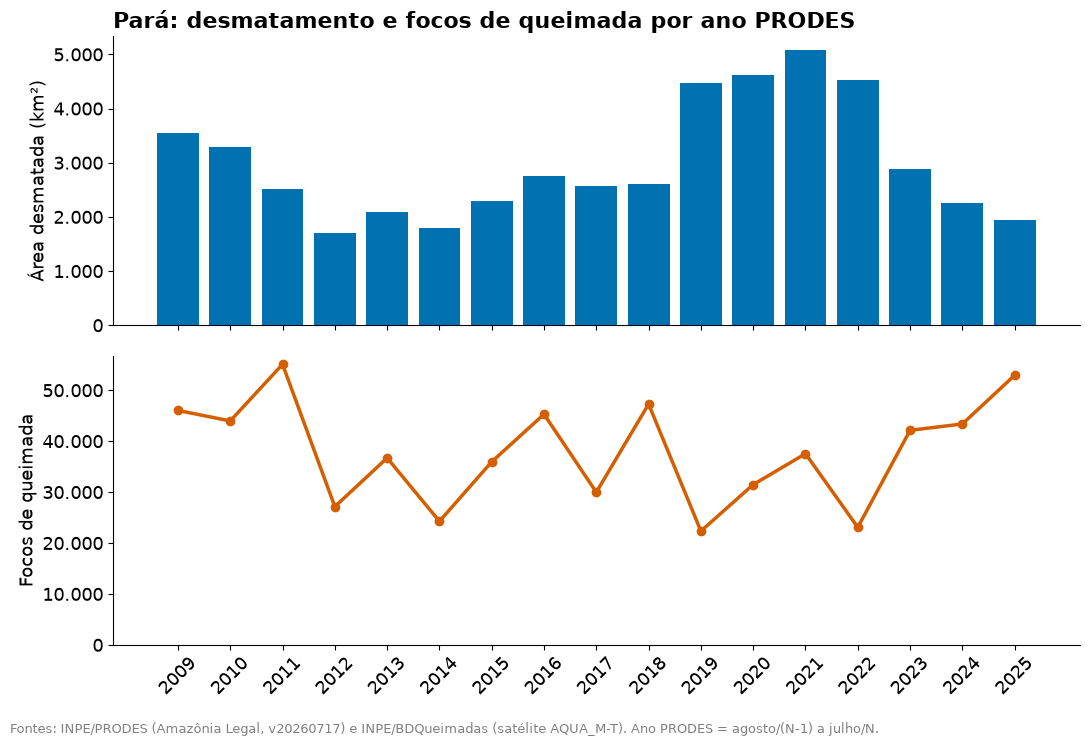

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)

ax1.bar(df["ano"], df["area_desmatada_km2"], color=COR_DESMAT)
ax1.set_ylabel("Área desmatada (km²)")
ax1.set_title("Pará: desmatamento e focos de queimada por ano PRODES", loc="left")
ax1.yaxis.set_major_formatter(FuncFormatter(milhar))

ax2.plot(df["ano"], df["qtd_focos"], color=COR_FOGO, marker="o", linewidth=2.5)
ax2.set_ylabel("Focos de queimada")
ax2.set_ylim(bottom=0)
ax2.set_xticks(df["ano"])
ax2.tick_params(axis="x", rotation=45)
ax2.yaxis.set_major_formatter(FuncFormatter(milhar))

fig.text(0.01, 0.01, FONTE, fontsize=9, color="gray")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(PASTA_FIGURAS / "01_serie_por_ano.png", dpi=200)
plt.show()

## 2. Dispersão: área desmatada x focos
Cada ponto é um ano. A cor separa dois períodos; as linhas tracejadas são a tendência de cada um. O corte em 2018 foi escolhido depois de olhar os dados, então a divisão é exploratória.

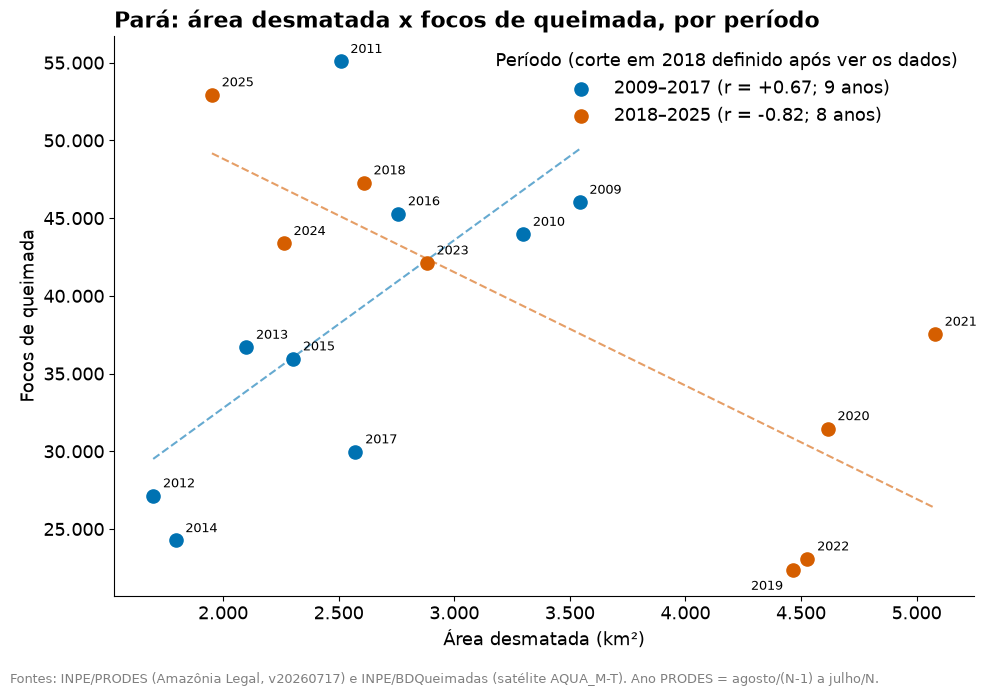

In [10]:
AJUSTE_ROTULO = {2019: (-30, -14)}  # evita sobrepor os rótulos de 2019 e 2022

fig, ax = plt.subplots(figsize=(10, 7))

for periodo, g in df.groupby("periodo"):
    x, y = g["area_desmatada_km2"], g["qtd_focos"]
    r = x.corr(y)
    ax.scatter(x, y, s=90, color=CORES[periodo], zorder=3,
               label=f"{periodo} (r = {r:+.2f}; {len(g)} anos)")
    for _, linha in g.iterrows():
        ano = int(linha["ano"])
        deslocamento = AJUSTE_ROTULO.get(ano, (7, 6))
        ax.annotate(str(ano), (linha["area_desmatada_km2"], linha["qtd_focos"]),
                    textcoords="offset points", xytext=deslocamento, fontsize=9)
    a, b = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, a * xs + b, linestyle="--", color=CORES[periodo], alpha=0.6)

ax.set_xlabel("Área desmatada (km²)")
ax.set_ylabel("Focos de queimada")
ax.set_title("Pará: área desmatada x focos de queimada, por período", loc="left")
ax.xaxis.set_major_formatter(FuncFormatter(milhar))
ax.yaxis.set_major_formatter(FuncFormatter(milhar))
ax.legend(title="Período (corte em 2018 definido após ver os dados)", frameon=False)

fig.text(0.01, 0.01, FONTE, fontsize=9, color="gray")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(PASTA_FIGURAS / "02_dispersao.png", dpi=200)
plt.show()

## 3. Focos por km² desmatado
Mostra quanto fogo houve para cada km² de desmatamento novo em cada ano. É uma razão descritiva, não uma medida de causa.

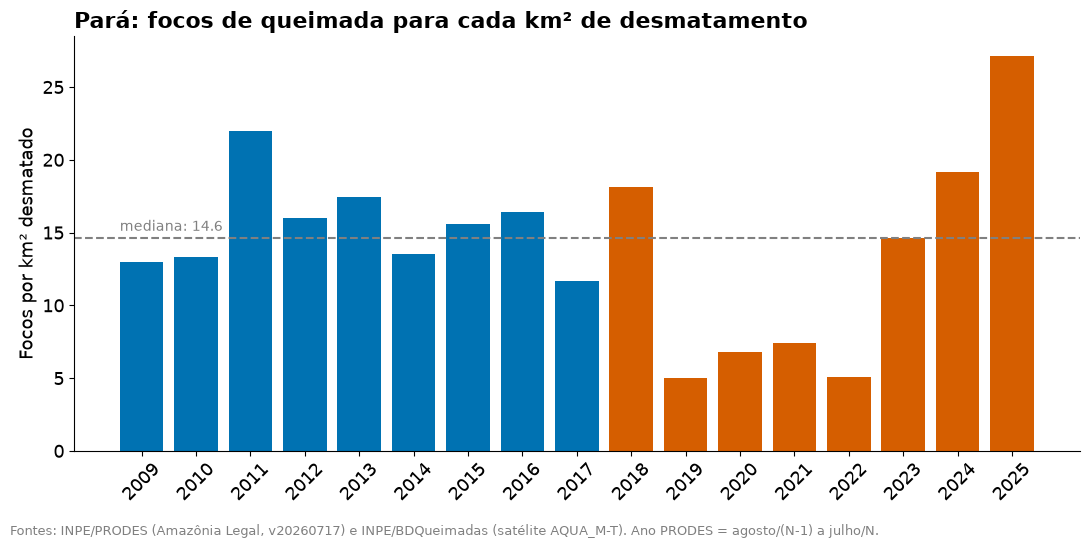

In [11]:
fig, ax = plt.subplots(figsize=(11, 5.5))

ax.bar(df["ano"], df["focos_por_km2"], color=[CORES[p] for p in df["periodo"]])
mediana = df["focos_por_km2"].median()
ax.axhline(mediana, linestyle="--", color="gray")
ax.text(df["ano"].min() - 0.4, mediana + 0.5, f"mediana: {mediana:.1f}", color="gray", fontsize=10)

ax.set_ylabel("Focos por km² desmatado")
ax.set_xticks(df["ano"])
ax.tick_params(axis="x", rotation=45)
ax.set_title("Pará: focos de queimada para cada km² de desmatamento", loc="left")

fig.text(0.01, 0.01, FONTE, fontsize=9, color="gray")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(PASTA_FIGURAS / "03_focos_por_km2.png", dpi=200)
plt.show()

## 4. Correlações

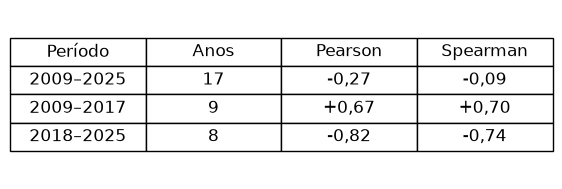

,Período,Anos,Pearson,Spearman
0,2009–2025,17,-0.27,-0.09
1,2009–2017,9,0.67,0.70
2,2018–2025,8,-0.82,-0.74


In [12]:
linhas = []
for nome, g in [("2009–2025", df), *df.groupby("periodo")]:
    linhas.append({
        "período": nome,
        "anos": len(g),
        "Pearson": g["area_desmatada_km2"].corr(g["qtd_focos"]),
        # Spearman = Pearson sobre os postos (evita depender do scipy)
        "Spearman": g["area_desmatada_km2"].rank().corr(g["qtd_focos"].rank()),
    })
tabela = pd.DataFrame(linhas).round(2)
tabela.columns = ["Período", "Anos", "Pearson", "Spearman"]

# salva a tabela como CSV e como imagem para os slides
(RAIZ / "data" / "processed").mkdir(parents=True, exist_ok=True)
tabela.to_csv(RAIZ / "data" / "processed" / "correlacoes.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 2.2))
ax.axis("off")
texto = [[r["Período"], str(r["Anos"]),
          f"{r['Pearson']:+.2f}".replace(".", ","), f"{r['Spearman']:+.2f}".replace(".", ",")]
         for _, r in tabela.iterrows()]
tbl = ax.table(cellText=texto, colLabels=tabela.columns, loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(12)
tbl.scale(1, 1.7)
fig.savefig(PASTA_FIGURAS / "04_correlacoes.png", dpi=200, bbox_inches="tight")
plt.show()
tabela

**Como ler estes números**
- Com 8 ou 9 anos por período, os coeficientes são frágeis: descrevem estes dados, não provam relação de causa.
- Focos de queimada contam qualquer fogo no estado (pasto, lavoura, manejo, floresta em pé). O PRODES conta só desmatamento novo.
- O nível estadual esconde onde as coisas acontecem; a comparação por município é o próximo passo.